# 01 — Decision Tree (CART) | Deteksi Situs Web Phishing
**PIC:** Laura (Anggota 1 — Project Lead & Decision Tree CART)  
**Dataset:** Data hasil preprocessing bersama tim (`dataset/output/`) dari [UCI Phishing Websites (ID: 327)](https://archive.ics.uci.edu/dataset/327/phishing+websites)  
- `X_train.csv` / `y_train.csv`: 4.679 sampel latih (30 fitur diskrit `{-1, 0, 1}`)
- `X_test.csv` / `y_test.csv`: 1.170 sampel uji
- Target biner (`Result`): `0` = Legitimate (Aman), `1` = Phishing (Berbahaya)
- **Metrik Prioritas:** Recall (Phishing) agar situs berbahaya tidak lolos sebagai aman.

**Luaran yang dihasilkan notebook ini (sesuai standar repo Kelompok 4):**
1. `models/decision_tree_model.pkl` (model terlatih untuk `app/app.py`)
2. `evaluation/decision_tree_metrics.json` (format metrik seragam untuk Leaderboard & Streamlit)
3. `evaluation/decision_tree/` (diagram pohon keputusan `decision_tree_plot.png`, ekstraksi aturan `aturan_if_then_laura.txt`, Confusion Matrix, ROC-PR curve, Feature Importance, dan prediksi uji)

In [1]:
import json
import time
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text, _tree
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    roc_curve,
    precision_recall_curve,
    average_precision_score,
    confusion_matrix,
    classification_report,
)

sns.set_theme(style='whitegrid')
RANDOM_STATE = 42

# Deteksi otomatis path folder repo (berjalan lancar di lokal maupun Google Colab)
candidate_data_dirs = [
    Path('../dataset/output'),
    Path('dataset/output'),
    Path('.'),
]
DATA_DIR = next((d for d in candidate_data_dirs if (d / 'X_train.csv').exists()), None)
if DATA_DIR is None:
    raise FileNotFoundError(
        'File X_train.csv tidak ditemukan. Jika memakai Google Colab, unggah 4 file '
        '(X_train.csv, y_train.csv, X_test.csv, y_test.csv) dari folder dataset/output/ '
        'ke panel Files di sisi kiri Colab.'
    )

if DATA_DIR == Path('../dataset/output'):
    BASE_OUT = Path('..')
else:
    BASE_OUT = Path('output_laura_github')

MODELS_DIR = BASE_OUT / 'models'
EVAL_DIR = BASE_OUT / 'evaluation'
DT_EVAL_DIR = EVAL_DIR / 'decision_tree'
for folder in [MODELS_DIR, EVAL_DIR, DT_EVAL_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

print(f'[OK] Membaca data dari : {DATA_DIR.resolve()}')
print(f'[OK] Folder output     : {BASE_OUT.resolve()}')

[OK] Membaca data dari : /content
[OK] Folder output     : /content/output_laura_github


## 1. Memuat Data Hasil Preprocessing Tim (`dataset/output/`)
Sesuai aturan tim di `notebooks/README.md`: kita langsung menggunakan `X_train.csv`, `y_train.csv`, `X_test.csv`, dan `y_test.csv` tanpa mengacak ulang split dan tanpa mengubah huruf besar-kecil nama kolom. Untuk Decision Tree, tidak diperlukan *scaling* (`needs_scaling: False`).

In [2]:
X_train = pd.read_csv(DATA_DIR / 'X_train.csv')
y_train = pd.read_csv(DATA_DIR / 'y_train.csv').squeeze()
X_test = pd.read_csv(DATA_DIR / 'X_test.csv')
y_test = pd.read_csv(DATA_DIR / 'y_test.csv').squeeze()

feature_cols = list(X_train.columns)
print(f'X_train: {X_train.shape} | y_train: {y_train.shape}')
print(f'X_test : {X_test.shape}  | y_test : {y_test.shape}')
print('Distribusi y_train:', y_train.value_counts().sort_index().to_dict())
print('Distribusi y_test :', y_test.value_counts().sort_index().to_dict())
X_train.head(3)

X_train: (4679, 30) | y_train: (4679,)
X_test : (1170, 30)  | y_test : (1170,)
Distribusi y_train: {0: 2264, 1: 2415}
Distribusi y_test : {0: 566, 1: 604}


,having_IP_Address,URL_Length,Shortining_Service,having_At_Symbol,double_slash_redirecting,Prefix_Suffix,having_Sub_Domain,SSLfinal_State,Domain_registeration_length,Favicon,...,RightClick,popUpWidnow,Iframe,age_of_domain,DNSRecord,web_traffic,Page_Rank,Google_Index,Links_pointing_to_page,Statistical_report
0,1,-1,1,-1,1,-1,0,1,1,1,...,1,1,1,1,-1,-1,1,1,1,-1
1,1,-1,1,1,1,-1,-1,1,-1,1,...,1,1,1,1,-1,1,-1,1,1,1
2,1,-1,1,1,1,-1,0,1,1,1,...,1,1,1,-1,1,1,-1,1,0,1


## 2. Hyperparameter Tuning & Training Decision Tree (CART / Gini)
Kita mencari kombinasi hyperparameter terbaik menggunakan 5-Fold Stratified Cross-Validation dengan fokus pada **F1-Score & Recall** kelas Phishing (`1`), lalu mengukur waktu latih murni (`Train Time (s)`) pada `X_train`.

In [3]:
param_grid = {
    'criterion': ['gini'],
    'max_depth': [4, 6, 8, 10, 12, 15, None],
    'min_samples_split': [2, 5, 10, 20],
    'min_samples_leaf': [1, 2, 4, 8],
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
grid = GridSearchCV(
    DecisionTreeClassifier(random_state=RANDOM_STATE),
    param_grid=param_grid,
    scoring={'recall': 'recall', 'f1': 'f1', 'roc_auc': 'roc_auc'},
    refit='f1',
    cv=cv,
    n_jobs=-1,
    return_train_score=False,
)
grid.fit(X_train, y_train)

best_params = grid.best_params_
print('Best Parameters (CART):', best_params)

# Simpan ringkasan CV
cv_df = pd.DataFrame(grid.cv_results_)[
    ['param_max_depth', 'param_min_samples_split', 'param_min_samples_leaf',
     'mean_test_recall', 'mean_test_f1', 'mean_test_roc_auc', 'rank_test_f1']
].sort_values('rank_test_f1')
cv_df.to_csv(DT_EVAL_DIR / 'cv_summary.csv', index=False)

# Latih ulang model final untuk mencatat Train Time (s) secara akurat
best_dt = DecisionTreeClassifier(**best_params, random_state=RANDOM_STATE)
t0 = time.perf_counter()
best_dt.fit(X_train, y_train)
train_time = round(time.perf_counter() - t0, 4)
print(f'Train Time: {train_time:.4f} detik | Kedalaman pohon: {best_dt.get_depth()} | Jumlah daun: {best_dt.get_n_leaves()}')

Best Parameters (CART): {'criterion': 'gini', 'max_depth': 12, 'min_samples_leaf': 1, 'min_samples_split': 10}
Train Time: 0.0153 detik | Kedalaman pohon: 12 | Jumlah daun: 174


## 3. Evaluasi Model & Ekspor File Standar Tim
Menyimpan:
- `models/decision_tree_model.pkl`
- `evaluation/decision_tree_metrics.json` (format identik dengan `knn_metrics.json` dan `logistic_regression_metrics.json`)
- `evaluation/decision_tree/confusion_matrix.png`, `roc_pr.png`, dan `test_predictions.csv`

In [4]:
y_pred = best_dt.predict(X_test)
y_prob = best_dt.predict_proba(X_test)[:, 1]

metrics_summary = {
    'Algoritma': 'Decision Tree (CART)',
    'PIC': 'Laura',
    'best_params': best_params,
    'Accuracy': round(float(accuracy_score(y_test, y_pred)), 4),
    'Precision (Phishing)': round(float(precision_score(y_test, y_pred)), 4),
    'Recall (Phishing)': round(float(recall_score(y_test, y_pred)), 4),
    'F1-Score (Phishing)': round(float(f1_score(y_test, y_pred)), 4),
    'ROC-AUC': round(float(roc_auc_score(y_test, y_prob)), 4),
    'Train Time (s)': train_time,
}

# 1. Simpan model ke models/decision_tree_model.pkl
model_path = MODELS_DIR / 'decision_tree_model.pkl'
joblib.dump(best_dt, model_path)

# 2. Simpan metrik ke evaluation/decision_tree_metrics.json
metrics_path = EVAL_DIR / 'decision_tree_metrics.json'
metrics_path.write_text(json.dumps(metrics_summary, indent=2), encoding='utf-8')

# 3. Simpan prediksi uji
pd.DataFrame({
    'y_true': y_test.values,
    'y_pred': y_pred,
    'y_prob_phishing': np.round(y_prob, 6),
}).to_csv(DT_EVAL_DIR / 'test_predictions.csv', index=False)

print('=== RINGKASAN METRIK (decision_tree_metrics.json) ===')
print(json.dumps(metrics_summary, indent=2))
print('\n=== Classification Report ===')
print(classification_report(y_test, y_pred, target_names=['Legitimate (0)', 'Phishing (1)']))

=== RINGKASAN METRIK (decision_tree_metrics.json) ===
{
  "Algoritma": "Decision Tree (CART)",
  "PIC": "Laura",
  "best_params": {
    "criterion": "gini",
    "max_depth": 12,
    "min_samples_leaf": 1,
    "min_samples_split": 10
  },
  "Accuracy": 0.9231,
  "Precision (Phishing)": 0.9386,
  "Recall (Phishing)": 0.9106,
  "F1-Score (Phishing)": 0.9244,
  "ROC-AUC": 0.9693,
  "Train Time (s)": 0.0153
}

=== Classification Report ===
                precision    recall  f1-score   support

Legitimate (0)       0.91      0.94      0.92       566
  Phishing (1)       0.94      0.91      0.92       604

      accuracy                           0.92      1170
     macro avg       0.92      0.92      0.92      1170
  weighted avg       0.92      0.92      0.92      1170



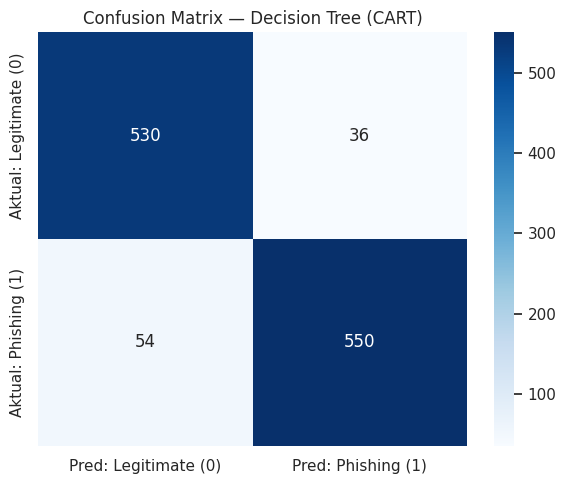

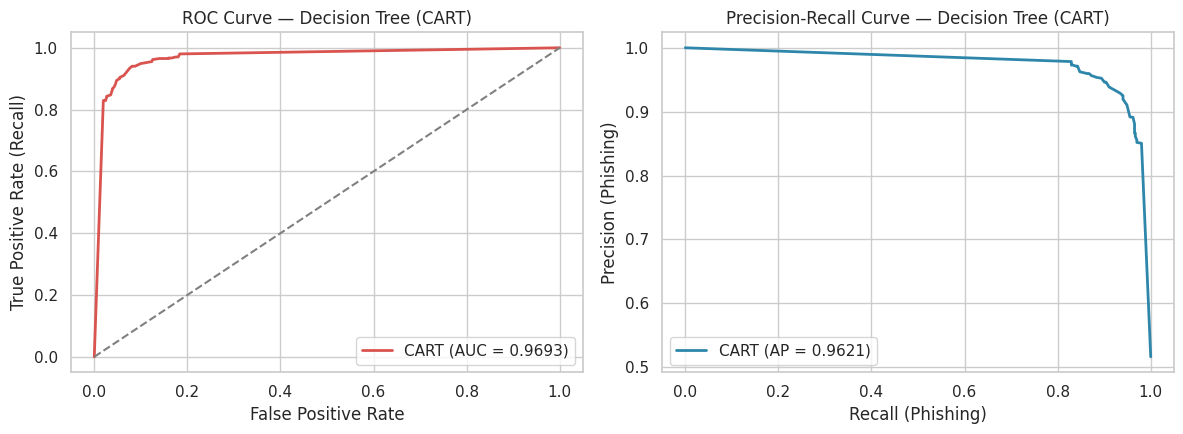

In [5]:
# Plot 1: Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6, 5))
sns.heatmap(
    cm, annot=True, fmt='d', cmap='Blues',
    xticklabels=['Pred: Legitimate (0)', 'Pred: Phishing (1)'],
    yticklabels=['Aktual: Legitimate (0)', 'Aktual: Phishing (1)'],
)
plt.title('Confusion Matrix — Decision Tree (CART)')
plt.tight_layout()
plt.savefig(DT_EVAL_DIR / 'confusion_matrix.png', dpi=200, bbox_inches='tight')
plt.show()

# Plot 2: ROC Curve & Precision-Recall Curve
fpr, tpr, _ = roc_curve(y_test, y_prob)
prec, rec, _ = precision_recall_curve(y_test, y_prob)
ap_score = average_precision_score(y_test, y_prob)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].plot(fpr, tpr, color='#D9534F', lw=2, label=f'CART (AUC = {metrics_summary["ROC-AUC"]:.4f})')
axes[0].plot([0, 1], [0, 1], color='gray', linestyle='--')
axes[0].set_title('ROC Curve — Decision Tree (CART)')
axes[0].set_xlabel('False Positive Rate')
axes[0].set_ylabel('True Positive Rate (Recall)')
axes[0].legend(loc='lower right')

axes[1].plot(rec, prec, color='#2E86AB', lw=2, label=f'CART (AP = {ap_score:.4f})')
axes[1].set_title('Precision-Recall Curve — Decision Tree (CART)')
axes[1].set_xlabel('Recall (Phishing)')
axes[1].set_ylabel('Precision (Phishing)')
axes[1].legend(loc='lower left')

plt.tight_layout()
plt.savefig(DT_EVAL_DIR / 'roc_pr.png', dpi=200, bbox_inches='tight')
plt.show()

## 4. Luaran Khusus Anggota 1: Diagram Pohon Keputusan (Tree Plot), Aturan If-Then, & Feature Importance
Untuk visualisasi laporan dan ekstraksi aturan keamanan siber yang mudah dibaca, kita juga melatih pohon interpretabel (`max_depth=4`, `min_samples_leaf=20`).

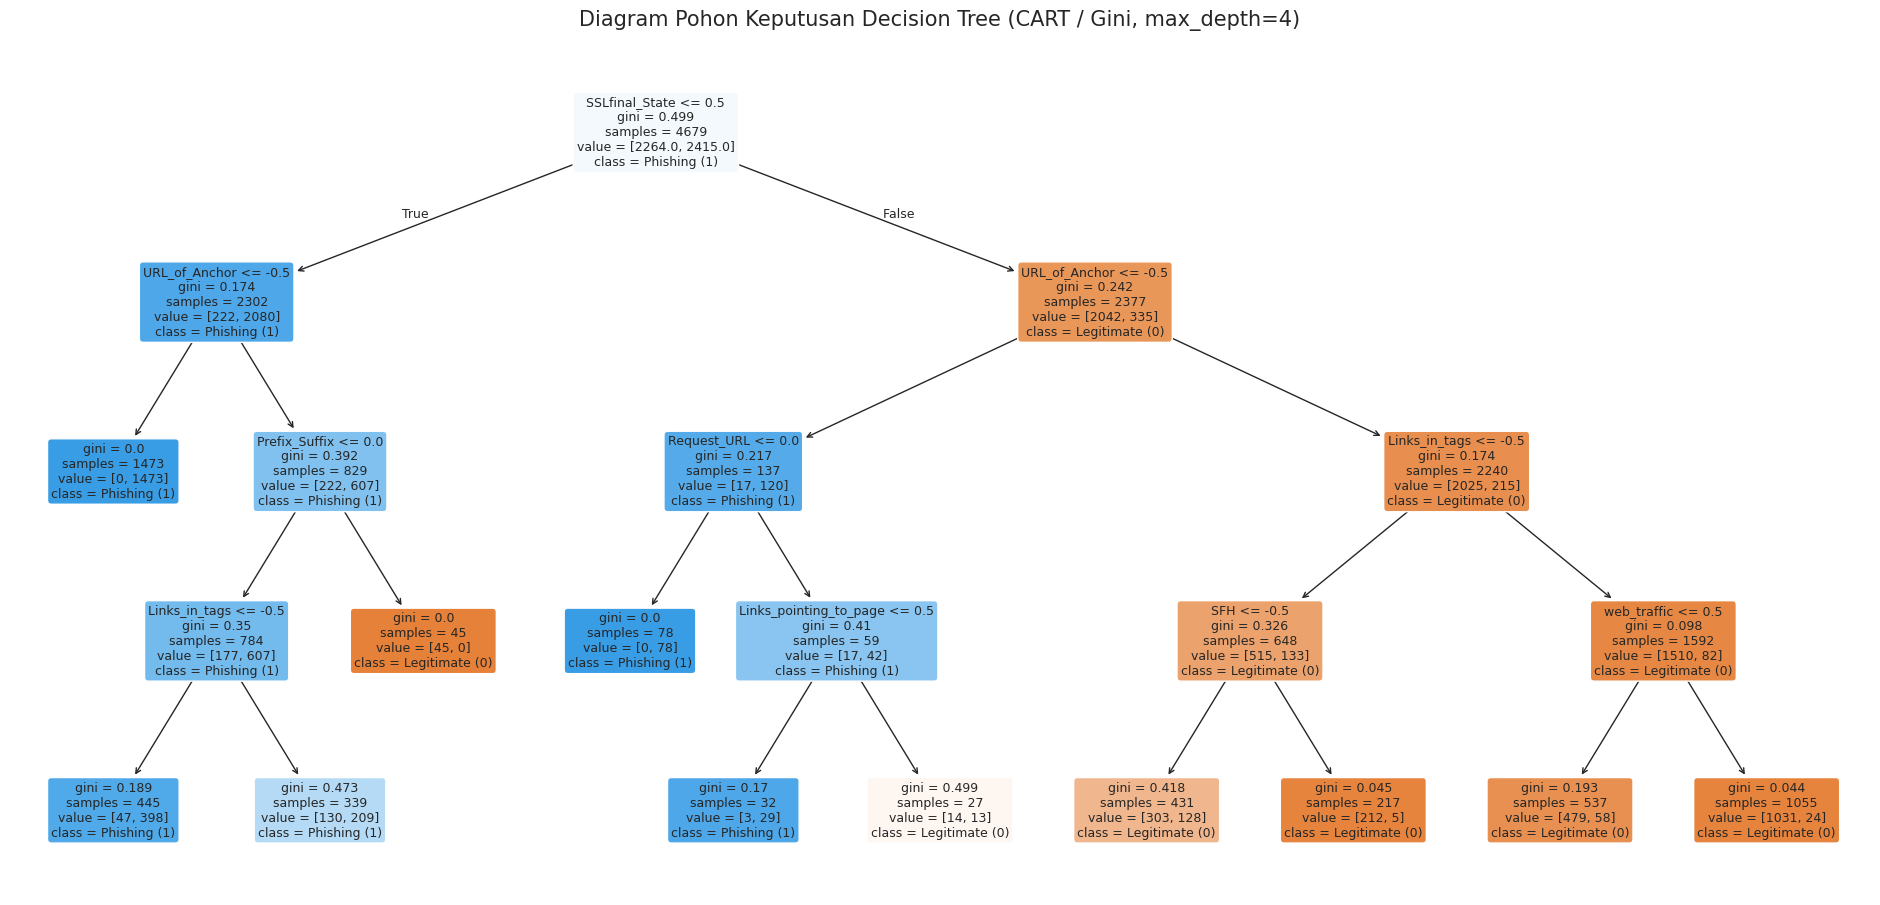

=== ATURAN IF-THEN KEAMANAN SIBER (CART) ===

Rule 1: JIKA SSLfinal_State <= 0.50 DAN URL_of_Anchor <= -0.50 MAKA Phishing (Keyakinan: 100.0%, Support: 1473 sampel)
Rule 2: JIKA SSLfinal_State <= 0.50 DAN URL_of_Anchor > -0.50 DAN Prefix_Suffix <= 0.00 DAN Links_in_tags <= -0.50 MAKA Phishing (Keyakinan: 89.4%, Support: 445 sampel)
Rule 3: JIKA SSLfinal_State <= 0.50 DAN URL_of_Anchor > -0.50 DAN Prefix_Suffix <= 0.00 DAN Links_in_tags > -0.50 MAKA Phishing (Keyakinan: 61.7%, Support: 339 sampel)
Rule 4: JIKA SSLfinal_State > 0.50 DAN URL_of_Anchor <= -0.50 DAN Request_URL <= 0.00 MAKA Phishing (Keyakinan: 100.0%, Support: 78 sampel)
Rule 5: JIKA SSLfinal_State > 0.50 DAN URL_of_Anchor <= -0.50 DAN Request_URL > 0.00 DAN Links_pointing_to_page <= 0.50 MAKA Phishing (Keyakinan: 90.6%, Support: 32 sampel)
Rule 6: JIKA SSLfinal_State > 0.50 DAN URL_of_Anchor > -0.50 DAN Links_in_tags > -0.50 DAN web_traffic > 0.50 MAKA Legitimate (Aman) (Keyakinan: 97.7%, Support: 1055 sampel)
Rule 7: JIK

In [6]:
# Model interpretabel (max_depth=4) khusus untuk diagram pohon & aturan if-then
interpretable_dt = DecisionTreeClassifier(
    criterion='gini', max_depth=4, min_samples_leaf=20, random_state=RANDOM_STATE
)
interpretable_dt.fit(X_train, y_train)

# 1. Visualisasi Diagram Pohon Keputusan
plt.figure(figsize=(24, 11))
plot_tree(
    interpretable_dt,
    feature_names=feature_cols,
    class_names=['Legitimate (0)', 'Phishing (1)'],
    filled=True,
    rounded=True,
    fontsize=9,
)
plt.title('Diagram Pohon Keputusan Decision Tree (CART / Gini, max_depth=4)', fontsize=15, pad=16)
plt.savefig(DT_EVAL_DIR / 'decision_tree_plot.png', dpi=300, bbox_inches='tight')
plt.show()

# 2. Ekstraksi Aturan If-Then
raw_rules_text = export_text(interpretable_dt, feature_names=feature_cols)
(DT_EVAL_DIR / 'aturan_if_then_raw.txt').write_text(raw_rules_text, encoding='utf-8')

def extract_if_then_rules(tree_model, feature_names, class_names=('Legitimate (Aman)', 'Phishing')):
    tree_ = tree_model.tree_
    feat_name = [
        feature_names[i] if i != _tree.TREE_UNDEFINED else 'undefined'
        for i in tree_.feature
    ]
    rules = []
    def recurse(node, conditions):
        if tree_.feature[node] != _tree.TREE_UNDEFINED:
            name = feat_name[node]
            thr = tree_.threshold[node]
            recurse(tree_.children_left[node], conditions + [f'{name} <= {thr:.2f}'])
            recurse(tree_.children_right[node], conditions + [f'{name} > {thr:.2f}'])
        else:
            counts = tree_.value[node][0]
            total = counts.sum()
            pred_idx = int(np.argmax(counts))
            conf = (counts[pred_idx] / total * 100) if total > 0 else 0.0
            rules.append({
                'prediksi': class_names[pred_idx],
                'support': int(tree_.n_node_samples[node]),
                'aturan': f'JIKA {" DAN ".join(conditions)} MAKA {class_names[pred_idx]} (Keyakinan: {conf:.1f}%, Support: {int(tree_.n_node_samples[node])} sampel)',
            })
    recurse(0, [])
    return sorted(rules, key=lambda r: (r['prediksi'] != 'Phishing', -r['support']))

rules_list = extract_if_then_rules(interpretable_dt, feature_cols)
rules_output = '\n'.join(f'Rule {i+1}: {r["aturan"]}' for i, r in enumerate(rules_list))
(DT_EVAL_DIR / 'aturan_if_then_laura.txt').write_text(rules_output, encoding='utf-8')
print('=== ATURAN IF-THEN KEAMANAN SIBER (CART) ===\n')
print(rules_output)

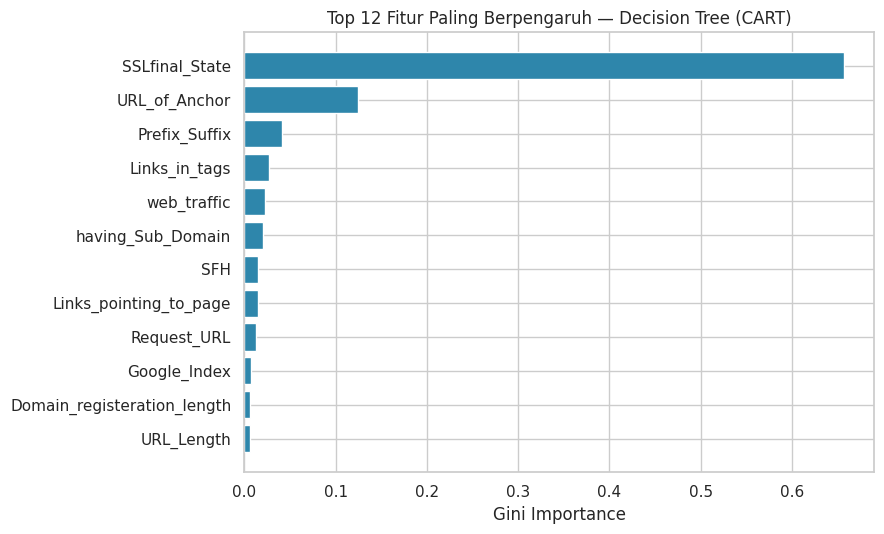

,feature,importance
7,SSLfinal_State,0.657192
13,URL_of_Anchor,0.124635
5,Prefix_Suffix,0.041014
14,Links_in_tags,0.026388
25,web_traffic,0.022159
6,having_Sub_Domain,0.020717
15,SFH,0.015043
28,Links_pointing_to_page,0.014639
12,Request_URL,0.012472
27,Google_Index,0.007622


In [7]:
# 3. Feature Importance dari Model Best CART
fi_df = pd.DataFrame({
    'feature': feature_cols,
    'importance': best_dt.feature_importances_,
}).sort_values('importance', ascending=False)
fi_df.to_csv(DT_EVAL_DIR / 'feature_importance.csv', index=False)

plt.figure(figsize=(9, 5.5))
top_fi = fi_df.head(12).iloc[::-1]
plt.barh(top_fi['feature'], top_fi['importance'], color='#2E86AB')
plt.title('Top 12 Fitur Paling Berpengaruh — Decision Tree (CART)')
plt.xlabel('Gini Importance')
plt.tight_layout()
plt.savefig(DT_EVAL_DIR / 'feature_importance.png', dpi=200, bbox_inches='tight')
plt.show()
fi_df.head(10)

In [8]:
# (Khusus Google Colab) Zip semua hasil agar mudah diunduh sekaligus
if BASE_OUT == Path('output_laura_github'):
    import shutil
    shutil.make_archive('output_laura_github', 'zip', BASE_OUT)
    print('[OK] File siap diunduh: output_laura_github.zip')
    print('Isi folder di dalam zip:')
    for p in sorted(BASE_OUT.rglob('*')):
        if p.is_file():
            print(' -', p.relative_to(BASE_OUT))
else:
    print('[OK] Semua file sudah langsung tersimpan ke folder models/ dan evaluation/ di repo!')

[OK] File siap diunduh: output_laura_github.zip
Isi folder di dalam zip:
 - evaluation/decision_tree/aturan_if_then_laura.txt
 - evaluation/decision_tree/aturan_if_then_raw.txt
 - evaluation/decision_tree/confusion_matrix.png
 - evaluation/decision_tree/cv_summary.csv
 - evaluation/decision_tree/decision_tree_plot.png
 - evaluation/decision_tree/feature_importance.csv
 - evaluation/decision_tree/feature_importance.png
 - evaluation/decision_tree/roc_pr.png
 - evaluation/decision_tree/test_predictions.csv
 - evaluation/decision_tree_metrics.json
 - models/decision_tree_model.pkl
